# Monte Carlo: prueba pequeña de una call asiática geométrica

La cartera es **CAT, MRK y MSFT**. Sus volatilidades y correlaciones proceden de rendimientos logarítmicos diarios del **5 de enero de 2016 al 31 de diciembre de 2025**. Esa ventana histórica calibra los parámetros; el horizonte futuro del contrato es de **cinco años**.

Por indicación de clase, comenzamos con **10 pasos y 10 trayectorias**, en una única ejecución. Una **semilla fija** permite repetir exactamente el experimento. Mostramos las **primeras cinco trayectorias** en tablas y gráficos. La semilla no hace que las trayectorias se parezcan entre sí.

Todas las operaciones del notebook están vectorizadas, sin bucles `for` o `while`. Esta prueba verifica el funcionamiento, no proporciona una valoración definitiva: el enunciado final requiere 20 observaciones y al menos 1.000 trayectorias.

**Entradas:** `outputs/parametros_montecarlo.json` y `Datos/Transformados/dowjones_diario_2016_2025.csv`. Se lee el CSV limpio y se comprueba que reproduce los parámetros del equipo; no se limpia, modifica ni exporta ningún dato. La simulación conserva los parámetros del JSON.


In [1]:
# Dependencias: numpy, pandas y matplotlib.
from __future__ import annotations

import json
from dataclasses import dataclass
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
COLORES = ("#004481", "#2DCCCD", "#1973B8")


## 1. Configuración

El orden debe coincidir en `activos`, `volatilidades` y `correlacion`. Los valores de respaldo coinciden con el JSON del equipo.

`semilla=42` reproduce las diez trayectorias al ejecutar de nuevo el notebook. Mostramos las primeras cinco como ejemplos, pero valoramos la opción con las diez.

Con diez observaciones futuras en cinco años, $\Delta t=5/10=0.5$ años. $t_0$ se conserva para los gráficos y los rendimientos, pero no se incluye en la media geométrica del payoff.


In [2]:
@dataclass(frozen=True)
class ConfiguracionMonteCarlo:
    activos: tuple[str, ...] = ("CAT", "MRK", "MSFT")
    s0: tuple[float, ...] = (1.0, 1.0, 1.0)
    volatilidades: tuple[float, ...] = (0.304449, 0.226614, 0.267572)
    correlacion: tuple[tuple[float, ...], ...] = (
        (1.0, 0.249833, 0.394764),
        (0.249833, 1.0, 0.276564),
        (0.394764, 0.276564, 1.0),
    )
    tipo_libre_riesgo: float = 0.01
    strike: float = 3.0
    ttm: float = 5.0
    num_pasos: int = 10
    num_trayectorias: int = 10
    semilla: int = 42

    @property
    def dt(self) -> float:
        return self.ttm / self.num_pasos


ruta_parametros = Path("outputs/parametros_montecarlo.json")
if ruta_parametros.is_file():
    with ruta_parametros.open(encoding="utf-8") as archivo:
        parametros = json.load(archivo)
    # El JSON del equipo almacena sigma con forma (1, 3).
    config = ConfiguracionMonteCarlo(
        activos=tuple(parametros["tickers"]),
        volatilidades=tuple(np.asarray(parametros["sigma"], dtype=float).reshape(-1)),
        correlacion=np.asarray(parametros["rho"], dtype=float),
    )
    periodo_historico = parametros["periodo"]
    origen_parametros = str(ruta_parametros)
else:
    config = ConfiguracionMonteCarlo()
    periodo_historico = {"inicio": "2016-01-05", "fin": "2025-12-31"}
    origen_parametros = "Copia del JSON del equipo (consulta del 05-10-2026)"

print("Origen de parámetros:", origen_parametros)
print("Ventana histórica de retornos:", periodo_historico)
print(f"Prueba: {config.num_trayectorias} trayectorias × {config.num_pasos} pasos")
print(f"Horizonte futuro: {config.ttm} años | Δt: {config.dt} años")
print("Semilla:", config.semilla)
print(pd.DataFrame({
    "Activo": config.activos,
    "S0": config.s0,
    "Volatilidad anual": config.volatilidades,
}).to_string(index=False))


Origen de parámetros: outputs\parametros_montecarlo.json
Ventana histórica de retornos: {'inicio': '2016-01-05', 'fin': '2025-12-31'}
Prueba: 10 trayectorias × 10 pasos
Horizonte futuro: 5.0 años | Δt: 0.5 años
Semilla: 42
Activo  S0  Volatilidad anual
   CAT 1.0           0.304449
   MRK 1.0           0.226614
  MSFT 1.0           0.267572


## 1.1. Comprobación del CSV limpio

Ejecutar este notebook desde la raíz del repositorio. Se utiliza `close`, igual que en la selección de cartera del equipo. Solo leemos CAT, MRK y MSFT para comprobar sus datos; si faltan precios o hay duplicados, detenemos la ejecución en lugar de corregirlos.

A partir de los precios calculamos rendimientos simples con `pct_change` y logarítmicos con `np.log(P_t/P_{t-1})`. La primera fecha no tiene un precio anterior y no genera un rendimiento. No se eliminan observaciones adicionales.

Comprobamos la volatilidad logarítmica anualizada con 252 sesiones y la correlación de los rendimientos logarítmicos. Se admite únicamente el redondeo a seis decimales del JSON de Daniel. Esta comprobación no cambia los parámetros ni reejecuta los notebooks de otros integrantes.


In [3]:
ruta_csv = Path("Datos/Transformados/dowjones_diario_2016_2025.csv")
if not ruta_csv.is_file():
    raise FileNotFoundError(
        "Falta el CSV limpio en Datos/Transformados. "
        "Abre la carpeta del repositorio y ejecuta desde su raíz."
    )

datos_limpios = pd.read_csv(
    ruta_csv, usecols=["symbol", "date", "close"], parse_dates=["date"]
)
datos_cartera = datos_limpios.loc[
    datos_limpios["symbol"].isin(config.activos), ["symbol", "date", "close"]
]
if datos_cartera.empty or datos_cartera.isna().any().any():
    raise ValueError("La cartera está vacía o contiene datos ausentes. No se limpian automáticamente.")
if datos_cartera.duplicated(["date", "symbol"]).any():
    raise ValueError("Hay fechas duplicadas para una acción. Revisar el CSV con el equipo.")

precios_historicos = datos_cartera.pivot(
    index="date", columns="symbol", values="close"
).loc[:, list(config.activos)]
if (len(precios_historicos) < 3
        or not np.isfinite(precios_historicos.to_numpy(dtype=float)).all()
        or (precios_historicos <= 0).any().any()):
    raise ValueError("Se requieren precios positivos, finitos y alineados para los tres activos.")

# La primera observación no tiene un precio previo; no se omite ningún dato posterior.
retornos_simples_historicos = precios_historicos.pct_change(fill_method=None).iloc[1:]
retornos_historicos = np.log(
    precios_historicos / precios_historicos.shift(1)
).iloc[1:]
assert np.allclose(
    retornos_historicos.to_numpy(),
    np.log1p(retornos_simples_historicos.to_numpy()),
)
sigma_csv = retornos_historicos.std(ddof=1).to_numpy() * np.sqrt(252)
rho_csv = retornos_historicos.corr().to_numpy()
periodo_csv = {
    "inicio": str(retornos_historicos.index.min().date()),
    "fin": str(retornos_historicos.index.max().date()),
}
if periodo_csv != periodo_historico:
    raise ValueError("El periodo de retornos del CSV no coincide con el JSON del equipo.")
if not np.allclose(sigma_csv, config.volatilidades, rtol=0, atol=5.1e-7):
    raise ValueError("La volatilidad del CSV no coincide con el JSON: revisar las entradas con el equipo.")
if not np.allclose(rho_csv, config.correlacion, rtol=0, atol=5.1e-7):
    raise ValueError("La correlación del CSV no coincide con el JSON: revisar las entradas con el equipo.")

print("CSV leído sin modificar:", ruta_csv)
print("Filas del CSV:", len(datos_limpios), "| Acciones:", datos_limpios["symbol"].nunique())
print("Precios diarios por activo:", len(precios_historicos))
print("Rendimientos diarios por activo:", len(retornos_historicos))
print("Periodo de precios:", precios_historicos.index.min().date(), "a", precios_historicos.index.max().date())
print("Periodo de retornos:", periodo_csv)
print(pd.DataFrame({
    "Activo": config.activos,
    "Sigma desde CSV": sigma_csv,
    "Sigma del equipo": config.volatilidades,
    "Diferencia": sigma_csv - np.asarray(config.volatilidades),
}).to_string(index=False))
print("Sigma y rho coinciden con el JSON dentro de su redondeo a seis decimales.")


CSV leído sin modificar: Datos\Transformados\dowjones_diario_2016_2025.csv
Filas del CSV: 64557 | Acciones: 26
Precios diarios por activo: 2514
Rendimientos diarios por activo: 2513
Periodo de precios: 2016-01-04 a 2025-12-31
Periodo de retornos: {'inicio': '2016-01-05', 'fin': '2025-12-31'}
Activo  Sigma desde CSV  Sigma del equipo    Diferencia
   CAT         0.304449          0.304449  1.032153e-07
   MRK         0.226614          0.226614  1.948242e-07
  MSFT         0.267572          0.267572 -1.762606e-07
Sigma y rho coinciden con el JSON dentro de su redondeo a seis decimales.


## 2. Validación de parámetros

La volatilidad ya está anualizada: no volvemos a multiplicarla por $\sqrt{252}$. La tasa de crecimiento para valorar la opción es el 1 % libre de riesgo, no la rentabilidad histórica de las acciones.

Para una matriz triangular inferior $L$, Cholesky cumple $\rho=LL^\top$. Los vectores normales por filas se correlacionan mediante `Z @ L.T`.


In [4]:
def validar_configuracion(config: ConfiguracionMonteCarlo) -> np.ndarray:
    s0 = np.asarray(config.s0, dtype=float)
    sigma = np.asarray(config.volatilidades, dtype=float)
    rho = np.asarray(config.correlacion, dtype=float)
    escalares = np.asarray(
        [config.tipo_libre_riesgo, config.strike, config.ttm], dtype=float
    )
    conteos = np.asarray([
        config.num_pasos, config.num_trayectorias
    ])
    if len(config.activos) != 3 or len(set(config.activos)) != 3:
        raise ValueError("Se requieren tres activos distintos.")
    if s0.shape != (3,) or sigma.shape != (3,) or rho.shape != (3, 3):
        raise ValueError("Dimensiones esperadas: S0 y sigma (3,), rho (3, 3).")
    if not (np.isfinite(s0).all() and np.isfinite(sigma).all()
            and np.isfinite(rho).all() and np.isfinite(escalares).all()):
        raise ValueError("Todos los parámetros numéricos deben ser finitos.")
    if np.any(s0 <= 0) or np.any(sigma < 0) or config.ttm <= 0 or config.strike < 0:
        raise ValueError("S0 y T deben ser positivos; sigma y strike no negativos.")
    if np.any(conteos < 1) or np.any(conteos != np.floor(conteos)):
        raise ValueError("Pasos y trayectorias deben ser enteros positivos.")
    if not np.allclose(rho, rho.T) or not np.allclose(np.diag(rho), 1):
        raise ValueError("rho debe ser simétrica y tener diagonal 1.")
    if np.any(np.abs(rho) > 1):
        raise ValueError("Las correlaciones deben estar entre -1 y 1.")
    if not isinstance(config.semilla, (int, np.integer)) or config.semilla < 0:
        raise ValueError("La semilla debe ser un entero no negativo.")
    return np.linalg.cholesky(rho)


L = validar_configuracion(config)
print("Parámetros válidos. Factor de Cholesky:")
print(L)
assert np.allclose(L @ L.T, np.asarray(config.correlacion))


Parámetros válidos. Factor de Cholesky:
[[1.       0.       0.      ]
 [0.249833 0.968289 0.      ]
 [0.394764 0.183766 0.900217]]


## 3. Trayectorias mediante movimiento browniano geométrico

$$
S_j^k=S_{j-1}^k\exp\left[
\left(r-\frac{\sigma_k^2}{2}\right)\Delta t+
\sigma_k\sqrt{\Delta t}\,Z_j^k\right].
$$

Los incrementos logarítmicos correlacionados se acumulan con `np.cumsum` sobre el eje temporal. `X` tiene ejes **(trayectoria, tiempo, activo)** y forma **(10, 10, 3)**.

La media geométrica y la prima se calcularán sobre las trayectorias individuales, sin promediar sus precios previamente.


In [5]:
def simular_trayectorias(
    config: ConfiguracionMonteCarlo,
) -> tuple[np.ndarray, np.ndarray]:
    """Genera precios e innovaciones correlacionadas con semilla reproducible."""
    L = validar_configuracion(config)
    rng = np.random.default_rng(config.semilla)
    sigma = np.asarray(config.volatilidades, dtype=float)
    normales = rng.standard_normal((config.num_trayectorias, config.num_pasos, 3))
    innovaciones = normales @ L.T
    log_incrementos = (
        (config.tipo_libre_riesgo - 0.5 * sigma**2) * config.dt
        + sigma * np.sqrt(config.dt) * innovaciones
    )
    precios = np.asarray(config.s0) * np.exp(np.cumsum(log_incrementos, axis=1))
    return precios, innovaciones


inicio = perf_counter()
X, innovaciones = simular_trayectorias(config)
tiempo_simulacion = perf_counter() - inicio

tiempos = np.arange(1, config.num_pasos + 1) * config.dt
tiempos_con_t0 = np.concatenate(([0.0], tiempos))
X_con_t0 = np.concatenate((
    np.broadcast_to(np.asarray(config.s0), (config.num_trayectorias, 1, 3)),
    X,
), axis=1)
numero_ejemplos = min(5, config.num_trayectorias)

print("X (trayectorias, pasos, activos):", X.shape)
print(f"Tiempo de simulación: {tiempo_simulacion:.6f} s")


X (trayectorias, pasos, activos): (10, 10, 3)
Tiempo de simulación: 0.000391 s


## 4. Comprobaciones y primeras cinco trayectorias

En una muestra pequeña la correlación empírica puede diferir bastante de la objetivo. Se muestra como diagnóstico, sin exigir una tolerancia propia de una muestra grande.

La tabla presenta los precios finales de las primeras cinco trayectorias. Los gráficos muestran su recorrido completo, incluyendo $t_0$.


In [6]:
assert X.shape == (config.num_trayectorias, config.num_pasos, 3)
assert np.isfinite(X).all()
assert (X > 0).all()
assert np.isclose(tiempos[-1], config.ttm)

rho_objetivo = np.asarray(config.correlacion)
rho_simulada = np.corrcoef(innovaciones.reshape(-1, 3), rowvar=False)
desviacion_correlacion = np.max(np.abs(rho_simulada - rho_objetivo))

print("Precios positivos y finitos; dimensiones y vencimiento correctos.")
print("Correlación objetivo:\n", rho_objetivo)
print("Correlación de las innovaciones simuladas:\n", rho_simulada)
print(f"Desviación máxima en esta muestra pequeña: {desviacion_correlacion:.4f}")

tabla_primeras_cinco = pd.DataFrame(
    X[:numero_ejemplos, -1, :],
    columns=config.activos,
    index=pd.Index(np.arange(1, numero_ejemplos + 1), name="Trayectoria"),
)
print("\nPrecios finales de las primeras cinco trayectorias:")
print(tabla_primeras_cinco.round(6).to_string())


Precios positivos y finitos; dimensiones y vencimiento correctos.
Correlación objetivo:
 [[1.       0.249833 0.394764]
 [0.249833 1.       0.276564]
 [0.394764 0.276564 1.      ]]
Correlación de las innovaciones simuladas:
 [[1.       0.270459 0.39461 ]
 [0.270459 1.       0.439557]
 [0.39461  0.439557 1.      ]]
Desviación máxima en esta muestra pequeña: 0.1630

Precios finales de las primeras cinco trayectorias:
                  CAT       MRK      MSFT
Trayectoria                              
1            0.809330  0.963507  0.931769
2            1.870304  0.828182  1.378340
3            0.429160  0.700114  0.804145
4            0.667691  0.433010  0.455566
5            0.937724  1.096730  0.691314


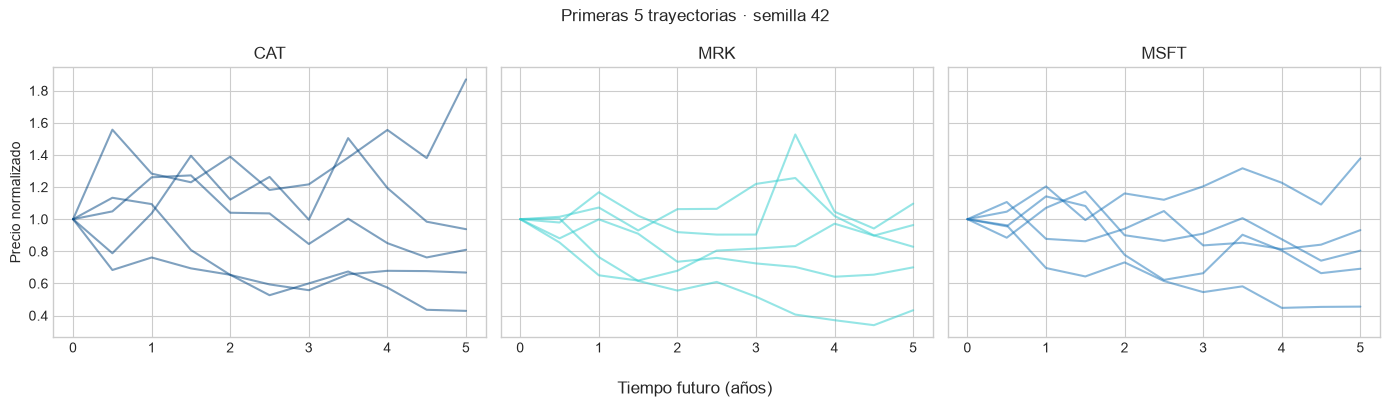

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
axes[0].plot(tiempos_con_t0, X_con_t0[:numero_ejemplos, :, 0].T, color=COLORES[0], alpha=0.5)
axes[1].plot(tiempos_con_t0, X_con_t0[:numero_ejemplos, :, 1].T, color=COLORES[1], alpha=0.5)
axes[2].plot(tiempos_con_t0, X_con_t0[:numero_ejemplos, :, 2].T, color=COLORES[2], alpha=0.5)
axes[0].set_title(config.activos[0])
axes[1].set_title(config.activos[1])
axes[2].set_title(config.activos[2])
axes[0].set_ylabel("Precio normalizado")
fig.supxlabel("Tiempo futuro (años)")
fig.suptitle(f"Primeras {numero_ejemplos} trayectorias · semilla {config.semilla}")
fig.tight_layout()
plt.show()


## 5. Rendimientos logarítmicos y pct_change

Los parámetros históricos proceden de rendimientos logarítmicos. Para comparar las dos magnitudes mostramos las rentabilidades de la **primera trayectoria simulada**, incluyendo $S_0$ antes de calcularlas:

$$r_{\text{simple}}=P_t/P_{t-1}-1,
\qquad r_{\log}=\ln(P_t/P_{t-1})=\ln(1+r_{\text{simple}}).$$

`pct_change` devuelve una fracción (0.05 significa 5 %). Estos rendimientos son semestrales en esta prueba, no diarios. La tabla es una comprobación didáctica; el payoff se calcula con los precios.


In [8]:
precios_ejemplo = pd.DataFrame(
    X_con_t0[0], index=tiempos_con_t0, columns=config.activos
)
precios_ejemplo.index.name = "Tiempo (años)"
rendimientos_simples = precios_ejemplo.pct_change(fill_method=None).iloc[1:]
rendimientos_logaritmicos = np.log(
    precios_ejemplo / precios_ejemplo.shift(1)
).iloc[1:]

assert np.allclose(
    rendimientos_logaritmicos.to_numpy(),
    np.log1p(rendimientos_simples.to_numpy()),
)
comparacion_retornos = pd.concat({
    "Simple (%)": rendimientos_simples * 100,
    "Logarítmico (%)": rendimientos_logaritmicos * 100,
}, axis=1)
print(comparacion_retornos.round(3).to_string())


              Simple (%)                 Logarítmico (%)                
                     CAT     MRK    MSFT             CAT     MRK    MSFT
Tiempo (años)                                                           
0.5                4.857 -14.530  10.685           4.743 -15.700  10.152
1.0               20.239 -23.883 -20.727          18.431 -27.291 -23.227
1.5                0.939  -5.047  -1.706           0.935  -5.179  -1.721
2.0              -18.275   9.906   9.028         -20.181   9.446   8.644
2.5               -0.395  18.496  11.723          -0.396  16.971  11.085
3.0              -18.385   1.509 -20.354         -20.316   1.498 -22.758
3.5               18.642   1.978   1.968          17.094   1.958   1.949
4.0              -15.190  16.718  -4.646         -16.476  15.459  -4.757
4.5              -10.451  -7.654   3.410         -11.038  -7.962   3.353
5.0                6.237   7.340  10.752           6.050   7.083  10.213


## 6. Payoff por trayectoria y prima inicial

Para cada activo se calcula la media geométrica de sus $m$ observaciones futuras normalizadas. En esta prueba $m=10$:

$$
G_k=\exp\left(\frac{1}{m}\sum_{j=1}^{m}
\ln\frac{S_j^k}{S_0^k}\right),
\qquad V_T=\max(G_1+G_2+G_3-3,0).
$$

Primero se calcula el payoff de cada trayectoria. La prima inicial es el promedio de **los diez payoffs descontados**:

$$\widehat V_0=\exp(-rT)\frac{1}{n}\sum_{h=1}^n V_T^{(h)}.$$

Las primeras cinco trayectorias se muestran para revisar el cálculo. El error estándar estimado es orientativo con una muestra tan pequeña.


In [9]:
def calcular_payoff(
    precios: np.ndarray, s0: tuple[float, ...], strike: float
) -> tuple[np.ndarray, np.ndarray]:
    ratios = precios / np.asarray(s0)
    medias = np.exp(np.mean(np.log(ratios), axis=-2))
    payoff = np.maximum(medias.sum(axis=-1) - strike, 0.0)
    return payoff, medias


payoff, medias_geometricas = calcular_payoff(X, config.s0, config.strike)
descontados = payoff * np.exp(-config.tipo_libre_riesgo * config.ttm)
prima_t0 = descontados.mean()
error_estandar = (
    descontados.std(ddof=1) / np.sqrt(descontados.size)
    if descontados.size > 1 else np.nan
)

assert payoff.shape == (config.num_trayectorias,)
assert np.all(payoff >= 0)

tabla_payoffs = pd.DataFrame({
    "Trayectoria": np.arange(1, config.num_trayectorias + 1),
    "G CAT": medias_geometricas[:, 0],
    "G MRK": medias_geometricas[:, 1],
    "G MSFT": medias_geometricas[:, 2],
    "Payoff": payoff,
    "Payoff descontado t=0": descontados,
})
# Las etiquetas siguen el orden de activos que indique el JSON.
tabla_payoffs.columns = [
    "Trayectoria", *("G " + np.asarray(config.activos, dtype=str)),
    "Payoff", "Payoff descontado t=0",
]
print("Detalle de las primeras cinco trayectorias:")
print(tabla_payoffs.head(numero_ejemplos).round(6).to_string(index=False))
print(f"\nPrima inicial (media de las diez trayectorias): {prima_t0:.6f}")
print(f"Payoffs positivos: {(payoff > 0).mean():.1%}")
print(f"Error estándar estimado: {error_estandar:.6f}")
print("Diez trayectorias no permiten concluir que la valoración sea precisa.")


Detalle de las primeras cinco trayectorias:
 Trayectoria    G CAT    G MRK   G MSFT   Payoff  Payoff descontado t=0
           1 0.978712 0.799917 0.906995 0.000000                0.00000
           2 1.391790 1.029090 1.169125 0.590005                0.56123
           3 0.593288 0.762931 0.915418 0.000000                0.00000
           4 0.731074 0.532581 0.596396 0.000000                0.00000
           5 1.103147 1.037855 0.813179 0.000000                0.00000

Prima inicial (media de las diez trayectorias): 0.188087
Payoffs positivos: 30.0%
Error estándar estimado: 0.114756
Diez trayectorias no permiten concluir que la valoración sea precisa.


## 7. Objetivo Y: payoff final descontado a cada instante

Siguiendo la fórmula del reto:

$$Y_{h,j}=V_T^{(h)}\exp[-r(T-t_j)].$$

`Y` tiene forma **(10, 10)**: diez trayectorias y diez fechas futuras. En vencimiento, $Y=V_T$.

Este objetivo utiliza el payoff final realizado. Su media por fecha resume el efecto del descuento, **no una prima condicional recalculada con lo conocido en esa fecha**. La subida del resumen se explica por el menor descuento restante.

Las cinco trayectorias de ejemplo no son cinco fechas ni cinco ejecuciones distintas.


In [10]:
Y = payoff[:, None] * np.exp(
    -config.tipo_libre_riesgo * (config.ttm - tiempos)
)[None, :]
media_Y_por_instante = Y.mean(axis=0)

assert Y.shape == (config.num_trayectorias, config.num_pasos)
assert np.allclose(Y[:, -1], payoff)

tabla_temporal = pd.DataFrame({
    "Tiempo (años)": np.concatenate(([0.0], tiempos)),
    "Media del payoff descontado": np.concatenate(([prima_t0], media_Y_por_instante)),
})
print("Y (trayectorias, fechas):", Y.shape)
print(tabla_temporal.round(6).to_string(index=False))


Y (trayectorias, fechas): (10, 10)
 Tiempo (años)  Media del payoff descontado
           0.0                     0.188087
           0.5                     0.189030
           1.0                     0.189978
           1.5                     0.190930
           2.0                     0.191887
           2.5                     0.192849
           3.0                     0.193815
           3.5                     0.194787
           4.0                     0.195763
           4.5                     0.196744
           5.0                     0.197731


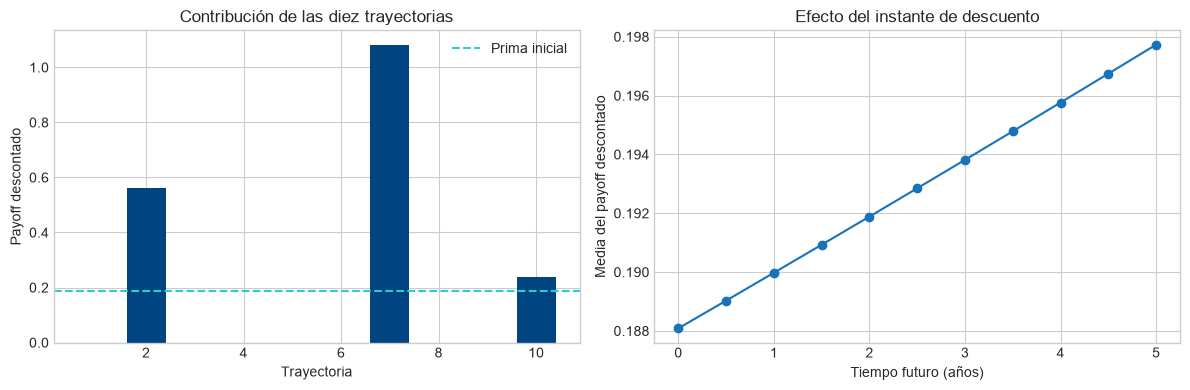

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(tabla_payoffs["Trayectoria"], descontados, color=COLORES[0])
axes[0].axhline(prima_t0, color=COLORES[1], linestyle="--", label="Prima inicial")
axes[0].set_xlabel("Trayectoria")
axes[0].set_ylabel("Payoff descontado")
axes[0].set_title("Contribución de las diez trayectorias")
axes[0].legend()
axes[1].plot(
    tabla_temporal["Tiempo (años)"],
    tabla_temporal["Media del payoff descontado"],
    "o-", color=COLORES[2],
)
axes[1].set_xlabel("Tiempo futuro (años)")
axes[1].set_ylabel("Media del payoff descontado")
axes[1].set_title("Efecto del instante de descuento")
fig.tight_layout()
plt.show()


## 8. Reproducibilidad de las primeras cinco trayectorias

La misma configuración y semilla deben reproducir los mismos números en este entorno. Comprobamos la igualdad de la muestra completa y de las cinco trayectorias mostradas.

La semilla se fija una vez al construir el generador; no se reinicia para cada trayectoria. De ese modo los recorridos son distintos y reproducibles.


In [12]:
X_repetida, innovaciones_repetidas = simular_trayectorias(config)
assert np.array_equal(X, X_repetida)
assert np.array_equal(innovaciones, innovaciones_repetidas)
assert np.array_equal(X[:numero_ejemplos], X_repetida[:numero_ejemplos])
payoff_repetido, _ = calcular_payoff(X_repetida, config.s0, config.strike)
assert np.array_equal(payoff, payoff_repetido)

print(f"Semilla {config.semilla}: las diez trayectorias se reproducen exactamente.")
print(f"Comprobadas las primeras {numero_ejemplos} trayectorias y sus payoffs.")


Semilla 42: las diez trayectorias se reproducen exactamente.
Comprobadas las primeras 5 trayectorias y sus payoffs.


## 9. Interpretación y siguiente ampliación

- El CSV limpio se comprueba en modo de solo lectura; no se modifican el JSON ni los notebooks de otros integrantes.
- Esta prueba usa los parámetros del equipo, **10 trayectorias y 10 observaciones futuras**, con semilla fija. Las primeras cinco trayectorias se presentan como ejemplos.
- La prima se estima con las diez trayectorias. Su diferencia respecto a una valoración con una muestra grande será ruido estadístico: la semilla permite reproducirlo, pero no lo reduce.
- `X` tiene forma `(10, 10, 3)`; `Y`, forma `(10, 10)`.
- Para la versión del enunciado habrá que configurar 20 observaciones y al menos 1.000 trayectorias, y estudiar precisión y tiempo con muestras mayores.
- El histórico 2016–2025 calibra $\sigma$ y $\rho$. El modelo futuro usa cinco años, tipo libre de riesgo del 1 %, parámetros constantes y ausencia de dividendos.
- Los resultados se expresan en unidades normalizadas; requieren un nominal para convertirlos a importes monetarios.

**Para practicar:** cambiar únicamente la semilla, ejecutar todas las celdas y observar las nuevas trayectorias y prima. Volver a 42 para recuperar exactamente la prueba original.
